# Exercise 2 - Mode Coupling

The gaussian field generator comes from Exercise 3, and can be checked at exercise_3.py. The power spectrum adopted in this exercise will be a simple power law, as we'll see.

In [1]:
import sys
sys.path.insert(0, '../E3') #Where the gaussian gen. is

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from exercise_3 import k_grid, gaussian_field, power_spectrum
from scipy.integrate import quad

OUT = Path('output')
OUT.mkdir(exist_ok=True)

### Parameters and FFT settings

In [2]:
N, L = 128, 1000.0 # mesh per dimension and box side in Mpc
n, k0 = -1.5, 0.1 # power-law slope and pivot in 1/Mpc
sigma8_target = 0.07 # top-hat rms on R = 8 Mpc/h with weakly nonlinear regime
h = 0.674 # to convert units in sigma_8. 

# Power-law linear spectrum (Mpc^3);; k in 1/Mpc
def P_pow(k, A=1.0):
    return A * (k / k0)**n

# FFT conversions for the convention delta(x) = (1/V) sum_k delta_k e^{ikx}
def to_x(dk, L):
    N = dk.shape[0]
    return np.fft.ifftn(dk).real * N**3 / L**3

def to_k(dx, L):
    N = dx.shape[0]
    return np.fft.fftn(dx) * L**3 / N**3

#Zero all modes with |k| > (2/3) k_Nyq (band limit against aliasing)
def cutaliasing(dk, L):
    N = dk.shape[0]
    *_, k = k_grid(N, L)
    out = dk.copy()
    out[k > (2/3) * np.pi * N / L] = 0
    return out

### Choosing the normalization of the power spectrum and plotting it. 

Note that the power spectrum of this exercise is really simple!

The power law amplitude is fixed on a physical scale, as for $\sigma_8$, with the spherical top-hat window:
$$\sigma_R^2 = \int_0^\infty \frac{k^2 P_L(k)}{2\pi^2}\,W^2(kR)\,dk, \qquad W(x) = \frac{3(\sin x - x\cos x)}{x^3},$$
with $R = 8\,h^{-1}$ Mpc and $\sigma_8 = 0.07$.

The rms of $\delta_1$ on the mesh is different: it is
$\sigma^2 = \frac{1}{V}\sum_\mathbf{k} P_L(k)$, a sharp-$k$ filter at the band limit
$k_c = \tfrac{2}{3}k_\mathrm{Nyq}$, so it changes with $N$ and $L$. It is printed only to show how linear the field is on this mesh. Normalizing on the mesh would change the physical spectrum whenever the resolution changes.

A = 6.615e+01 Mpc^3,  sigma_8 = 0.0700,  rms on the mesh sigma(delta_1) = 0.0989,  seed = 1


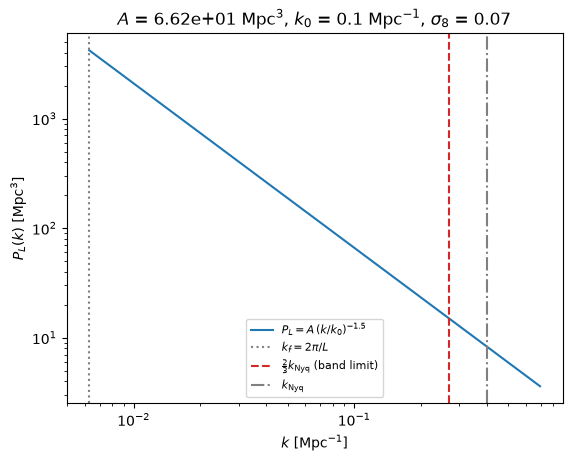

In [3]:
# Top-hat rms on scale R for P_pow; independent of the mesh.
def sigma_R(R, A=1.0):
    W = lambda x: 3 * (np.sin(x) - x * np.cos(x)) / x**3
    integrand = lambda lnk: np.exp(lnk)**3 * P_pow(np.exp(lnk), A) * W(np.exp(lnk) * R)**2 / (2 * np.pi**2)
    return np.sqrt(quad(integrand, np.log(1e-5), np.log(50), limit=500)[0])

R8 = 8 / h # 8 Mpc/h in Mpc
A = (sigma8_target / sigma_R(R8))**2 # sigma_R scales as sqrt(A)

seed = 1
dk1 = cutaliasing(gaussian_field(N, L, lambda k: P_pow(k, A), seed)[0], L)
dx1 = to_x(dk1, L)
print(f'A = {A:.3e} Mpc^3,  sigma_8 = {sigma_R(R8, A):.4f},  '
      f'rms on the mesh sigma(delta_1) = {dx1.std():.4f},  seed = {seed}')

# Adopted input spectrum and the scales of the box
kf  = 2 * np.pi / L # fundamental mode
kNy = np.pi * N / L # Nyquist frequency
k_plot = np.logspace(np.log10(kf), np.log10(np.sqrt(3) * kNy), 200)

plt.loglog(k_plot, P_pow(k_plot, A), label=fr'$P_L = A\,(k/k_0)^{{{n}}}$')
plt.axvline(kf, color='gray', ls=':', label=r'$k_f = 2\pi/L$')
plt.axvline(2/3 * kNy, color='C3', ls='--', label=r'$\frac{2}{3}k_\mathrm{Nyq}$ (band limit)')
plt.axvline(kNy, color='gray', ls='-.', label=r'$k_\mathrm{Nyq}$')
plt.xlabel(r'$k\ [\mathrm{Mpc}^{-1}]$'); plt.ylabel(r'$P_L(k)\ [\mathrm{Mpc}^3]$')
plt.title(fr'$A$ = {A:.2e} Mpc$^3$, $k_0$ = {k0} Mpc$^{{-1}}$, $\sigma_8$ = {sigma8_target}')
plt.legend(fontsize=8)
plt.savefig(OUT / 'input_spectrum.png', dpi=150)
plt.show()

### a) Determining the second order matter density

The convolution $\delta_{2,\mathbf{k}} = \frac{1}{V}\sum_\mathbf{q} F_2(\mathbf{q},\mathbf{k}-\mathbf{q})\,\delta_{1,\mathbf{q}}\delta_{1,\mathbf{k}-\mathbf{q}}$
costs $O(N^6)$ directly. Expanding $F_2$ we have in real space:
$$\delta_2(\mathbf{x}) = \tfrac{5}{7}\delta^2 - \nabla\delta\cdot\mathbf{u} + \tfrac{2}{7}\textstyle\sum_{ij}C_{ij}^2,
\qquad\qquad \mathbf{u}_\mathbf{k} = \frac{i\mathbf{k}}{k^2}\delta_\mathbf{k},\quad C_{ij,\mathbf{k}} = \frac{k_ik_j}{k^2}\delta_\mathbf{k},$$
which costs $O(N^3\log N)$ with FFTs. Recall that this kernel is related to the EdS regime.

### Treatment of the issues

- **Zero mode:** $\delta_{1,0} = 0$, and $1/k^2$ is set to 0 at $k = 0$. Also $F_2(\mathbf{q},-\mathbf{q}) = 0$, so $\langle\delta_2\rangle = 0$; $\delta_{2,0}$ is set to 0.
- **Band limit and aliasing:** $\delta_1$ is cut at $|k| < \tfrac{2}{3}k_\mathrm{Nyq}$. Products then reach at most $\tfrac{4}{3}k_\mathrm{Nyq}$, and the aliased copies fold back only above $\tfrac{2}{3}k_\mathrm{Nyq}$, so $\delta_2$ is exact, with no alias, after applying the same cut.
- **Nyquist:** with the 2/3 cut all Nyquist components are zero, so the derivative convention there does not matter.


Here, the growth factor is absorbed in the amplitude $A$ of the input spectrum: the epoch is set by $\sigma_8 = 0.07$, and no extra $D^2$ is applied to $\delta_2$.


In [4]:
# Second-order SPT density (EdS F2) via FFTs; dk1 must already be 2/3-cut.
def delta2(dk1, L):
    N = dk1.shape[0]
    kx, ky, kz, k = k_grid(N, L)
    ks = (kx, ky, kz)
    inv_k2 = np.zeros_like(k)
    inv_k2[k > 0] = 1 / k[k > 0]**2

    d    = to_x(dk1, L)
    grad = [to_x(1j * ki * dk1, L) for ki in ks] # grad delta
    u    = [to_x(1j * ki * inv_k2 * dk1, L) for ki in ks] # i k / k^2 delta
    C2   = sum(to_x(ks[i] * ks[j] * inv_k2 * dk1, L)**2 for i in range(3) for j in range(3))

    d2x = 5/7 * d**2 - sum(g * v for g, v in zip(grad, u)) + 2/7 * C2
    dk2 = to_k(d2x, L)
    dk2[0, 0, 0] = 0
    return cutaliasing(dk2, L)

dk2 = delta2(dk1, L)
dx2 = to_x(dk2, L)
print(f'sigma(delta_2) = {dx2.std():.4f},  sigma(delta_2)/sigma(delta_1) = {dx2.std()/dx1.std():.3f}')


sigma(delta_2) = 0.0187,  sigma(delta_2)/sigma(delta_1) = 0.189


### Validation of the $\delta_2$ function vs convolution

On a small mesh, the direct $O(N^6)$ sum
$\delta_{2,\mathbf{k}} = \frac{1}{V}\sum_\mathbf{q} F_2(\mathbf{q},\mathbf{k}-\mathbf{q})\,\delta_{1,\mathbf{q}}\delta_{1,\mathbf{k}-\mathbf{q}}$
is feasible. It uses the true vector $\mathbf{k}-\mathbf{q}$ and keeps only pairs where it is a mode of the mesh,
so it contains no aliasing. It is compared with the FFT construction, with and without the $2/3$ cut on $\delta_1$.

I'll test the convolution with $N = 16$ and $L = 100$. 

In [5]:
#Direct convolution with the kernel, using the true k - q, no aliasing.
def delta2_direct(dk1, L):
    N = dk1.shape[0]
    kx, ky, kz, k = k_grid(N, L)
    kvec = np.stack([kx, ky, kz], axis=-1).reshape(-1, 3) # all mode vectors
    kn, d = k.ravel(), dk1.ravel()
    idx = np.indices((N, N, N)).reshape(3, -1).T
    out = np.zeros(N**3, dtype=complex)
    for m, (a, b, c) in enumerate(idx): # loop over output k
        # index of the cell that stores k - q, for every q at once
        j = np.ravel_multi_index(((a - idx[:, 0]) % N, (b - idx[:, 1]) % N, (c - idx[:, 2]) % N), (N, N, N))
        q2 = kvec[m] - kvec # true vector
        ok = (kn > 0) & (kn[j] > 0) & np.all(np.isclose(q2, kvec[j]), axis=1) # drop zero modes and aliased pairs
        q1n, q2n = kn[ok], np.linalg.norm(q2[ok], axis=1)
        mu = np.einsum('ij,ij->i', kvec[ok], q2[ok]) / (q1n * q2n)
        F2 = 5/7 + mu/2 * (q1n/q2n + q2n/q1n) + 2/7 * mu**2
        out[m] = np.sum(F2 * d[ok] * d[j][ok]) / L**3
    out = out.reshape(N, N, N)
    out[0, 0, 0] = 0
    return cutaliasing(out, L)

Ns, Ls = 16, 100.0
dk_small = gaussian_field(Ns, Ls, P_pow, seed=3)[0]

for label, dk_in in [('with 2/3 cut', cutaliasing(dk_small, Ls)), ('without cut', dk_small)]:
    direct = delta2_direct(dk_in, Ls)
    err = np.abs(delta2(dk_in, Ls) - direct).max() / np.abs(direct).max()
    print(f'{label:14s} max|FFT - direct| / max|direct| = {err:.1e}')

with 2/3 cut   max|FFT - direct| / max|direct| = 4.6e-16
without cut    max|FFT - direct| / max|direct| = 6.5e-01


With the $2/3$ cut the FFT construction reproduces the direct sum to great precision. Without it, the
real-space products create modes above $k_\mathrm{Nyq}$ that fold back onto the mesh, and the error is of order unity.

### b) Comparing $\delta_1$ and $\delta_1 + \delta_2$. 

In exercise_3.py, I defined the power spectrum estimator $\hat{P}(k)$. Now, plotting the difference of the matter density with second order corrections. Note the effect of the cosmic variance.

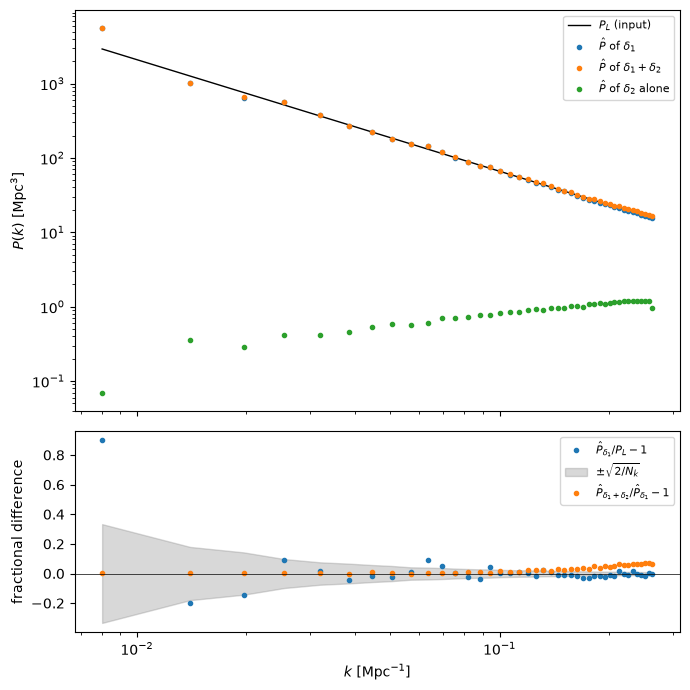

In [6]:
kmax = 2/3 * kNy # only modes inside the band limit
k_b, P1,  Nk = power_spectrum(dk1, L, kmax=kmax)
_,   P12, _  = power_spectrum(dk1 + dk2, L, kmax=kmax)
_,   P22, _  = power_spectrum(dk2, L, kmax=kmax) # power of delta_2 alone
err = np.sqrt(2 / Nk) # cosmic-variance relative error per shell

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(7, 7), gridspec_kw={'height_ratios': [2, 1]})
ax1.loglog(k_b, P_pow(k_b, A), 'k-', lw=1, label='$P_L$ (input)')
ax1.loglog(k_b, P1,  '.', label=r'$\hat P$ of $\delta_1$')
ax1.loglog(k_b, P12, '.', label=r'$\hat P$ of $\delta_1+\delta_2$')
ax1.loglog(k_b, P22, '.', label=r'$\hat P$ of $\delta_2$ alone')
ax1.set_ylabel(r'$P(k)\ [\mathrm{Mpc}^3]$'); ax1.legend(fontsize=8)

ax2.semilogx(k_b, P1/P_pow(k_b, A) - 1, '.', label=r'$\hat P_{\delta_1}/P_L - 1$')
ax2.fill_between(k_b, -err, err, color='gray', alpha=0.3, label=r'$\pm\sqrt{2/N_k}$')
ax2.semilogx(k_b, P12/P1 - 1, '.', label=r'$\hat P_{\delta_1+\delta_2}/\hat P_{\delta_1} - 1$')
ax2.axhline(0, color='k', lw=0.5)
ax2.set_xlabel(r'$k\ [\mathrm{Mpc}^{-1}]$'); ax2.set_ylabel('fractional difference'); ax2.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT / 'b_power_spectra.png', dpi=150); plt.show()

Adding $\delta_2$ changes the spectrum by
$P_{22} + 2P_{12}$. Since $\langle\delta_1\delta_2\rangle$ is an odd moment of a Gaussian field it vanishes on average, and
the change is dominated by $P_{22}$.
Note that this is not the full one-loop spectrum, which also contains $2P_{13}$ from the third-order field.
The two-point function is therefore only weakly sensitive to mode coupling and a higher-order statistic is needed.


Now, let us determine the reduced skewness $S_3(R)$, defined as
$$ S_3(R) = \frac{\langle \delta^3_R\rangle}{\langle \delta^2_R\rangle^2}.$$
**Window:** spherical top-hat, $W(x) = 3(\sin x - x\cos x)/x^3$. For the smoothing, we take $R = 20.0$ Mpc. At tree level, a power law with a top-hat window gives
$S_3 = 34/7 - (n+3)$ (Bernardeau 1994). It equals $3.357$ for $n = -1.5$.


In [7]:
# Fourier transform of the spherical top-hat window
def top_hat(k, R):
    x = k * R
    W = np.ones_like(x)
    nz = x > 0
    W[nz] = 3 * (np.sin(x[nz]) - x[nz] * np.cos(x[nz])) / x[nz]**3
    return W

def S3(dk, L, R):
    *_, k = k_grid(dk.shape[0], L)
    dR = to_x(top_hat(k, R) * dk, L)
    return np.mean(dR**3) / np.mean(dR**2)**2

R_S3 = 20.0 # Smoothing radius in Mpc
S3_tree = 34/7 - (n + 3) # Theory
print(f'S3(delta_1) = {S3(dk1, L, R_S3):.3f}   (Gaussian: 0)')
print(f'S3(delta_1+delta_2) = {S3(dk1 + dk2, L, R_S3):.3f} (tree level: {S3_tree:.3f})')

S3(delta_1) = 0.081   (Gaussian: 0)
S3(delta_1+delta_2) = 3.456 (tree level: 3.357)


Adding $\delta_2$ takes $S_3$ from $\approx 0$ to $\approx 3.46$, close to the tree-level value $3.36$, while the power spectrum
changed by only a few percent.  Mode coupling shows up clearly in the three-point statistic. A single finite box does not
give exactly $S_3 = 0$ for the Gaussian field ($0.08$ here).


### c) Multiple realizations and bispectrum measurement

**Estimator for equilateral bispectrum.** For each shell $S$ (width $\Delta k = 3k_f$ around $k$), keep only the modes of $\delta$ in $S$ and go back to real space: $\delta_S(\mathbf{x})$.
Averaging $\delta_S^3$ over the box sums $\delta_{\mathbf{k}_1}\delta_{\mathbf{k}_2}\delta_{\mathbf{k}_3}$ over all closed triangles with the three sides in $S$.
Dividing by the same sum for a field equal to 1 in $S$, $I_S(\mathbf{x})$, which counts the triangles, gives
$$\hat B(k) = \frac{1}{V}\,\frac{\sum_\mathbf{x}\delta_S^3}{\sum_\mathbf{x}I_S^3}.$$
Only shells below $\tfrac{2}{3}k_\mathrm{Nyq}$ are used, to avoid aliasing.

**Prediction.** $B_\mathrm{tree}$ is averaged over the same triangles as the estimator. This sum has the same structure as $\delta_2$. For a single exact equilateral triangle it reduces to the target $12P_L^2/7$.


In [8]:
# Shell masks. 1 for modes with kc - dk/2 <= |k| < kc + dk/2, else 0
def shell_mask(k, kc, dk):
    return ((k >= kc - dk/2) & (k < kc + dk/2)).astype(complex)

# Equilateral bispectrum estimator in one shell
def bispec_equil(delta_k, L, kc, dk):
    *_, k = k_grid(delta_k.shape[0], L)
    m = shell_mask(k, kc, dk)
    dS, IS = to_x(delta_k * m, L), to_x(m, L)
    return np.sum(dS**3) / (L**3 * np.sum(IS**3))

#Tree-level B averaged over the same triangles as the estimator
def btree_equil_binavg(N, L, kc, dk):
    *_, k = k_grid(N, L)
    m = shell_mask(k, kc, dk)
    PL = np.zeros_like(k); PL[k > 0] = P_pow(k[k > 0], A)
    IS = to_x(m, L)
    return 6 * np.sum(to_x(delta2(PL * m, L), L) * IS) / np.sum(IS**3)

# Triangle bins: width 3 k_f, all below the 2/3 band limit
dk_B = 3 * kf
kc_B = np.arange(5, 41, 5) * kf
kc_B = kc_B[kc_B + dk_B/2 <= 2/3 * kNy]

B_pred = np.array([btree_equil_binavg(N, L, kc, dk_B) for kc in kc_B])

#Known result from theory
B_point = 12 * P_pow(kc_B, A)**2 / 7

#Comparing the results
for kc, bp, b0 in zip(kc_B, B_pred, B_point):
    print(f'k = {kc:.3f}   <B_tree>_bin / (12 P^2/7) = {bp/b0:.3f}')

k = 0.031   <B_tree>_bin / (12 P^2/7) = 1.189
k = 0.063   <B_tree>_bin / (12 P^2/7) = 1.045
k = 0.094   <B_tree>_bin / (12 P^2/7) = 1.013
k = 0.126   <B_tree>_bin / (12 P^2/7) = 1.004
k = 0.157   <B_tree>_bin / (12 P^2/7) = 1.004
k = 0.188   <B_tree>_bin / (12 P^2/7) = 1.002
k = 0.220   <B_tree>_bin / (12 P^2/7) = 1.002
k = 0.251   <B_tree>_bin / (12 P^2/7) = 1.001


### Multiple realizations: using $N_{real}=50$

In [9]:
n_real = 50
seeds = 100 + np.arange(n_real)
S3_g, S3_nl = np.zeros(n_real), np.zeros(n_real)
B_g, B_nl = np.zeros((n_real, len(kc_B))), np.zeros((n_real, len(kc_B)))

for i, s in enumerate(seeds):
    dk1_s = cutaliasing(gaussian_field(N, L, lambda k: P_pow(k, A), s)[0], L)
    dk2_s = delta2(dk1_s, L)
    S3_g[i], S3_nl[i] = S3(dk1_s, L, R_S3), S3(dk1_s + dk2_s, L, R_S3)
    for j, kc in enumerate(kc_B):
        B_g[i, j]  = bispec_equil(dk1_s, L, kc, dk_B).real
        B_nl[i, j] = bispec_equil(dk1_s + dk2_s, L, kc, dk_B).real

mean_err = lambda x: (x.mean(axis=0), x.std(axis=0, ddof=1) / np.sqrt(x.shape[0]))

### Plotting their ratio and the bispectrum of $\delta_1$


For each realization $i$, the Gaussian and the weakly nonlinear statistics are measured on the
same linear field $\delta_1^{(i)}$, and their difference is taken before averaging:
$$\Delta\hat B^{(i)}(k) = \hat B\big[\delta_1^{(i)}+\delta_2^{(i)}\big](k) - \hat B\big[\delta_1^{(i)}\big](k).$$
The Gaussian term $\hat B[\delta_1]$ has zero mean but a large box-to-box scatter, and this sampling noise is almost the same in both
measurements because they share $\delta_1$. It cancels in the difference, which isolates the mode-coupling signal from $\delta_2$, such that
its ensemble mean estimates the same $B_\mathrm{tree}$, with a much smaller error. The same holds for $S_3$.


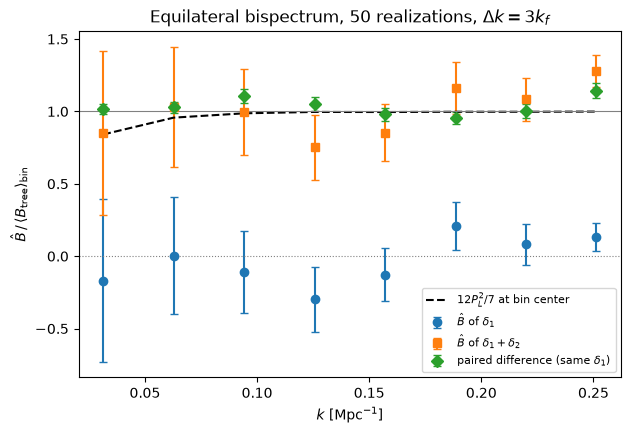


k [1/Mpc]           0.031  0.063  0.094  0.126  0.157  0.188  0.220  0.251
B(delta_1)/B_tree  -0.17 +0.00 -0.11 -0.30 -0.13 +0.21 +0.08 +0.13 
  error              0.56   0.41   0.29   0.22   0.18   0.17   0.14   0.09
B(d1+d2)/B_tree    +0.85 +1.03 +1.00 +0.75 +0.85 +1.16 +1.08 +1.28 
  error              0.56   0.41   0.30   0.23   0.20   0.18   0.15   0.11
paired diff/B_tree +1.02 +1.03 +1.11 +1.05 +0.98 +0.95 +1.00 +1.14 
  error              0.04   0.04   0.05   0.05   0.05   0.04   0.05   0.05

S3(delta_1)            0.041 +- 0.047   (scatter per box 0.334, tree/Gaussian target 0.000)
S3(delta_1+delta_2)    3.383 +- 0.048   (scatter per box 0.341, tree/Gaussian target 3.357)
S3 paired difference   3.342 +- 0.005   (scatter per box 0.033, tree/Gaussian target 3.357)


In [10]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for data, lab, mk in [(B_g, r'$\hat B$ of $\delta_1$', 'o'),
                      (B_nl, r'$\hat B$ of $\delta_1+\delta_2$', 's'),
                      (B_nl - B_g, 'paired difference (same $\\delta_1$)', 'D')]:
    m, e = mean_err(data / B_pred)
    ax.errorbar(kc_B, m, e, fmt=mk, capsize=3, label=lab)
ax.plot(kc_B, B_point / B_pred, 'k--', label=r'$12P_L^2/7$ at bin center')
ax.axhline(1, color='gray', lw=0.8); ax.axhline(0, color='gray', lw=0.8, ls=':')
ax.set_xlabel(r'$k\ [\mathrm{Mpc}^{-1}]$'); ax.set_ylabel(r'$\hat B\,/\,\langle B_\mathrm{tree}\rangle_\mathrm{bin}$')
ax.set_title(f'Equilateral bispectrum, {n_real} realizations, $\\Delta k = 3k_f$')
ax.legend(fontsize=8)
fig.savefig(OUT / 'c_bispectrum.png', dpi=150); plt.show()

#Bispectrum results
print('\nk [1/Mpc]         ', ' '.join(f'{kc:6.3f}' for kc in kc_B))
for lab, x in [('B(delta_1)/B_tree ', B_g), ('B(d1+d2)/B_tree   ', B_nl), ('paired diff/B_tree', B_nl - B_g)]:
    m, e = mean_err(x / B_pred)
    print(lab, ' '.join(f'{mm:+.2f}' for mm in m), '\n  error           ', ' '.join(f'{ee:6.2f}' for ee in e))

#Skewness results, requested for higher moments
print()
for lab, x, t in [('S3(delta_1)', S3_g, 0), ('S3(delta_1+delta_2)', S3_nl, S3_tree), ('S3 paired difference', S3_nl - S3_g, S3_tree)]:
    m, e = x.mean(), x.std(ddof=1) / np.sqrt(n_real)
    print(f'{lab:22s} {m:.3f} +- {e:.3f}   (scatter per box {x.std(ddof=1):.3f}, tree/Gaussian target {t:.3f})')


### d) Resolution, box size, realization scatter and amplitude

The function run_ensemble repeats the measurements of the skewness and bispectrum for any mesh, box and amplitude. The amplitude is always fixed by $\sigma_8$,
so changing $N$ or $L$ keeps the same physical $P_L$. Only bispectrum bins below the $2/3$ band limit of each mesh are used.
The cheap configuration $N = 64$, $L = 500$ Mpc has the same cell size (7.8 Mpc) as the main run and is used when many realizations are needed.

The comparisons are restricted to
well-resolved modes below the Nyquist scale.

In [11]:
def run_ensemble(N, L, sigma8, seeds, R=R_S3, kc_bins=kc_B, dk=dk_B):
    A_ = (sigma8 / sigma_R(R8))**2
    Pk = lambda k: P_pow(k, A_)
    *_, k = k_grid(N, L)
    kc_bins = kc_bins[kc_bins + dk/2 <= (2/3) * np.pi * N / L] # well-resolved bins only
    masks = [shell_mask(k, kc, dk) for kc in kc_bins]
    I3 = [np.sum(to_x(m, L)**3) for m in masks] # triangle counts
    PL = np.zeros_like(k); PL[k > 0] = Pk(k[k > 0])
    B_pred_ = np.array([6 * np.sum(to_x(delta2(PL * m, L), L) * to_x(m, L)) / i3 for m, i3 in zip(masks, I3)])
    WR = top_hat(k, R)

    def S3_of(dk_):
        d = to_x(WR * dk_, L)
        return np.mean(d**3) / np.mean(d**2)**2

    def B_of(dk_):
        return np.array([np.sum(to_x(dk_ * m, L)**3) / (L**3 * i3) for m, i3 in zip(masks, I3)])

    res = {'kc': kc_bins, 'B_pred': B_pred_, 'S3_g': [], 'S3_nl': [], 'B_g': [], 'B_nl': []}
    for s in seeds:
        d1 = cutaliasing(gaussian_field(N, L, Pk, s)[0], L)
        d12 = d1 + delta2(d1, L)
        res['S3_g'].append(S3_of(d1)); res['S3_nl'].append(S3_of(d12))
        res['B_g'].append(B_of(d1));   res['B_nl'].append(B_of(d12))
    for key in ('S3_g', 'S3_nl', 'B_g', 'B_nl'):
        res[key] = np.array(res[key])
    return res

def show(label, r):
    g, d = r['S3_g'], r['S3_nl'] - r['S3_g']
    nr = len(g)
    print(f'{label:26s} S3 Gaussian {g.mean():+.3f} +- {g.std(ddof=1)/np.sqrt(nr):.3f} (per box {g.std(ddof=1):.3f})   '
          f'S3 paired diff {d.mean():.3f} +- {d.std(ddof=1)/np.sqrt(nr):.3f}')

### Testing resolution 

For the bispectrum, all three meshes agree with tree level. A finer mesh just measures more points at higher $k$. Skewness on the coarsest mesh $S_3$ is too low. The mesh is too coarse for the smoothing radius, so the top-hat window is cut.
With finer meshes, $S_3$ agrees with tree level.

N = 64 (cell 15.6 Mpc)     S3 Gaussian -0.154 +- 0.109 (per box 0.489)   S3 paired diff 2.882 +- 0.011
N = 96 (cell 10.4 Mpc)     S3 Gaussian +0.090 +- 0.093 (per box 0.417)   S3 paired diff 3.371 +- 0.008
N = 128 (cell 7.8 Mpc)     S3 Gaussian +0.107 +- 0.071 (per box 0.317)   S3 paired diff 3.342 +- 0.009


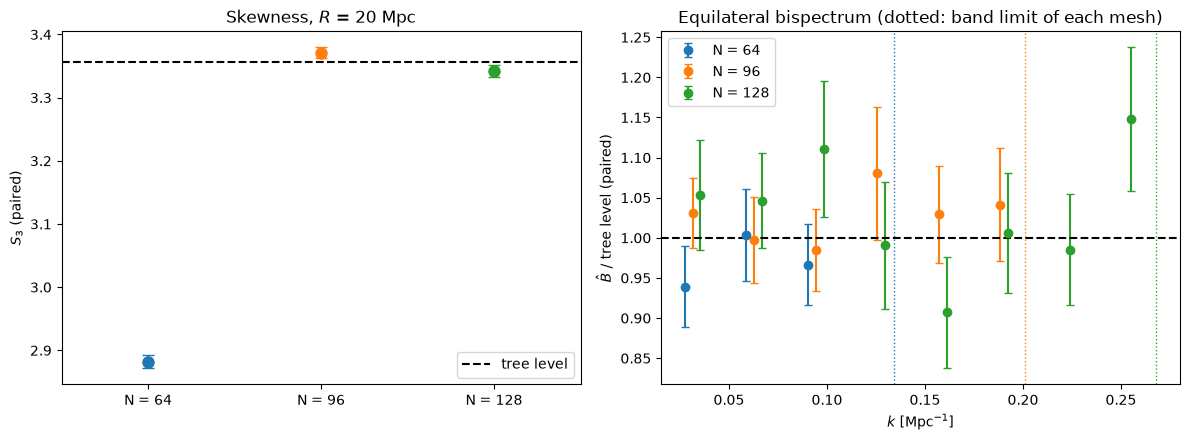

In [12]:
seeds_d = 100 + np.arange(20)
res_N = {Nm: run_ensemble(Nm, 1000.0, sigma8_target, seeds_d) for Nm in (64, 96, 128)}
for Nm, r in res_N.items():
    show(f'N = {Nm} (cell {1000/Nm:.1f} Mpc)', r)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
colors = {64: 'C0', 96: 'C1', 128: 'C2'}

# Left: S3 for each mesh
for i, (Nm, r) in enumerate(res_N.items()):
    d = r['S3_nl'] - r['S3_g']
    ax1.errorbar(i, d.mean(), d.std(ddof=1)/np.sqrt(len(d)), fmt='o', ms=8, capsize=4, color=colors[Nm])
ax1.axhline(S3_tree, color='k', ls='--', label='tree level')
ax1.set_xticks(range(3), [f'N = {Nm}' for Nm in res_N])
ax1.set_xlim(-0.5, 2.5)
ax1.set_ylabel(r'$S_3$ (paired)'); ax1.set_title(r'Skewness, $R$ = 20 Mpc'); ax1.legend()

# Right: bispectrum, points shifted slightly so they do not overlap
for i, (Nm, r) in enumerate(res_N.items()):
    m, e = mean_err((r['B_nl'] - r['B_g']) / r['B_pred'])
    shift = (i - 1) * 0.004
    ax2.errorbar(r['kc'] + shift, m, e, fmt='o', capsize=3, color=colors[Nm], label=f'N = {Nm}')
    ax2.axvline(2/3 * np.pi * Nm / 1000.0, color=colors[Nm], ls=':', lw=1)   # band limit of this mesh
ax2.axhline(1, color='k', ls='--')
ax2.set_xlabel(r'$k\ [\mathrm{Mpc}^{-1}]$'); ax2.set_ylabel(r'$\hat B$ / tree level (paired)')
ax2.set_title('Equilateral bispectrum (dotted: band limit of each mesh)'); ax2.legend()

fig.tight_layout(); fig.savefig(OUT / 'd_resolution.png', dpi=150); plt.show()

### Testing amplitude, box and number of realizations

Here the mesh is kept fixed and three things are varied:

- **Amplitude:** the same realizations are run with several values of $\sigma_8$.
  The Gaussian noise becomes relatively smaller as the amplitude increases.
- **Box size:** a smaller box with the same cell size is compared with the main run. A smaller volume contains fewer independent
  modes, so the scatter from box to box should be larger, while the mean values should not change.
- **Number of realizations:** the error of the ensemble mean is followed as more realizations are added. It should decrease
  roughly as one over the square root of the number of realizations.

In all cases, the paired difference is used to isolate the non-Gaussian signal from the finite-sampling noise.


sigma8 = 0.035 (N=64, L=500) S3 Gaussian +0.147 +- 0.166 (per box 1.655)   S3 paired diff 3.362 +- 0.009
sigma8 = 0.07 (N=64, L=500) S3 Gaussian +0.074 +- 0.083 (per box 0.828)   S3 paired diff 3.339 +- 0.009
sigma8 = 0.14 (N=64, L=500) S3 Gaussian +0.037 +- 0.041 (per box 0.414)   S3 paired diff 3.247 +- 0.008
sigma8 = 0.28 (N=64, L=500) S3 Gaussian +0.018 +- 0.021 (per box 0.207)   S3 paired diff 2.915 +- 0.007

per-box scatter of Gaussian S3: L=500 0.828, L=1000 0.317, ratio 2.61 (V^-1/2 predicts 2.83)
N_real =  10: error of mean S3_Gaussian = 0.337
N_real =  25: error of mean S3_Gaussian = 0.214
N_real =  50: error of mean S3_Gaussian = 0.137
N_real = 100: error of mean S3_Gaussian = 0.083


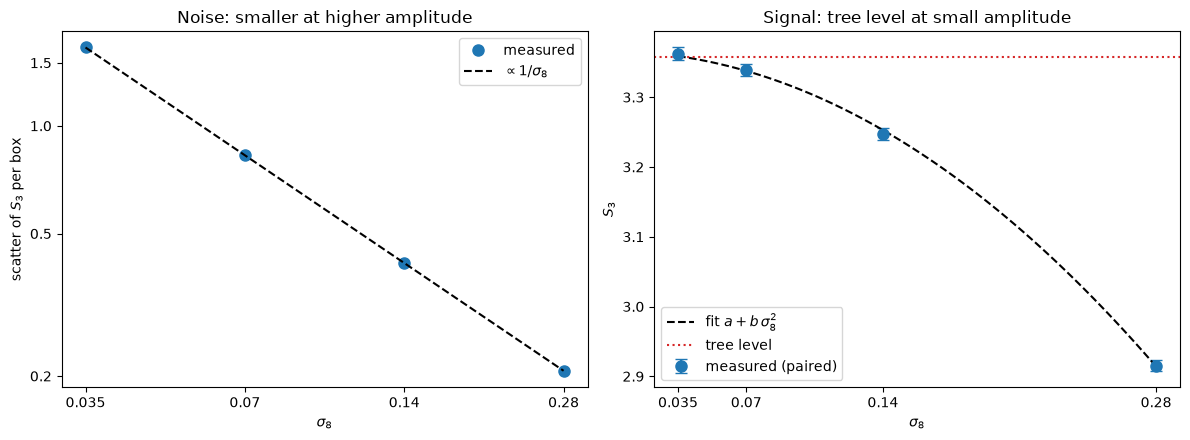

fit intercept (sigma8 -> 0) = 3.366,  tree level = 3.357


In [13]:
seeds_many = 100 + np.arange(100)
s8_values = [0.035, 0.07, 0.14, 0.28]
res_s8 = {s8: run_ensemble(64, 500.0, s8, seeds_many) for s8 in s8_values} # same cell size as N=128, L=1000
for s8, r in res_s8.items():
    show(f'sigma8 = {s8} (N=64, L=500)', r)

# Box size --- same cell but with volume 8x smaller
r_small, r_big = res_s8[sigma8_target], res_N[128]
print(f"\nper-box scatter of Gaussian S3: L=500 {r_small['S3_g'].std(ddof=1):.3f}, L=1000 {r_big['S3_g'].std(ddof=1):.3f}, "
      f"ratio {r_small['S3_g'].std(ddof=1)/r_big['S3_g'].std(ddof=1):.2f} (V^-1/2 predicts {np.sqrt(8):.2f})")

# Realization scatter: error of the mean vs number of realizations
for nr in (10, 25, 50, 100):
    x = r_small['S3_g'][:nr]
    print(f'N_real = {nr:3d}: error of mean S3_Gaussian = {x.std(ddof=1)/np.sqrt(nr):.3f}')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
s8 = np.array(s8_values)

# Left: noise of one box (Gaussian S3 scatter)
noise = np.array([res_s8[v]['S3_g'].std(ddof=1) for v in s8_values])
ax1.plot(s8, noise, 'o', ms=8, label='measured')
s8_fine = np.linspace(s8.min(), s8.max(), 100)
ax1.plot(s8_fine, noise[1] * sigma8_target / s8_fine, 'k--', label=r'$\propto 1/\sigma_8$')
ax1.set_xscale('log'); ax1.set_yscale('log')
ax1.set_xticks(s8, [f'{v}' for v in s8_values]); ax1.minorticks_off()
ax1.set_yticks([0.2, 0.5, 1.0, 1.5], ['0.2', '0.5', '1.0', '1.5'])
ax1.set_xlabel(r'$\sigma_8$'); ax1.set_ylabel(r'scatter of $S_3$ per box')
ax1.set_title('Noise: smaller at higher amplitude'); ax1.legend()

# Right: non-Gaussian signal (paired S3)
sig = np.array([(res_s8[v]['S3_nl'] - res_s8[v]['S3_g']).mean() for v in s8_values])
err = np.array([(res_s8[v]['S3_nl'] - res_s8[v]['S3_g']).std(ddof=1) / np.sqrt(len(seeds_many)) for v in s8_values])
slope, icpt = np.polyfit(s8**2, sig, 1)
ax2.errorbar(s8, sig, err, fmt='o', ms=8, capsize=4, label='measured (paired)')
ax2.plot(s8_fine, icpt + slope * s8_fine**2, 'k--', label=r'fit $a + b\,\sigma_8^2$')
ax2.axhline(S3_tree, color='C3', ls=':', label='tree level')
ax2.set_xticks(s8, [f'{v}' for v in s8_values])
ax2.set_xlabel(r'$\sigma_8$'); ax2.set_ylabel(r'$S_3$')
ax2.set_title('Signal: tree level at small amplitude'); ax2.legend()

fig.tight_layout(); fig.savefig(OUT / 'd_amplitude.png', dpi=150); plt.show()
print(f'fit intercept (sigma8 -> 0) = {icpt:.3f},  tree level = {S3_tree:.3f}')

The non-Gaussian signal created by mode coupling is the same in every box, such that it is fixed by the $F_2$ kerneland the input spectrum, and it agrees with tree level. Finite-sampling noise is a random fluctuation with zero mean and it changes from box to box and averages away with more volume or more realizations.

At small amplitude the signal matches tree level, but the noise of a single box is relatively large. At larger amplitude the noise is smaller, but higher-order terms start to pull the signal away from tree level.
